### Load results

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()

if not (ROOT / "outputs" / "tables").exists():
    ROOT = ROOT.parent

TABLE_DIR = ROOT / "outputs" / "tables"
FIGURE_DIR = ROOT / "outputs" / "figures"

sns.set_theme(style="whitegrid")

results = pd.read_csv(
    TABLE_DIR / "14_test_model_comparison.csv"
)

temporal = pd.read_csv(
    TABLE_DIR / "18_temporal_test_performance.csv"
)

ablation = pd.read_csv(
    TABLE_DIR / "20_graph_ablation_validation.csv"
)

validation = pd.read_csv(
    TABLE_DIR / "12_validation_model_comparison.csv"
)

print("All research results loaded successfully.")

All research results loaded successfully.


### Final model comparison

,Model,Precision,Recall,F1,AP,ROC_AUC
0,Baseline,0.9272,0.4681,0.6221,0.5479,0.8569
1,Graph_Only,0.0342,0.3284,0.0619,0.0369,0.3676
2,Combined,0.9272,0.4681,0.6221,0.5470,0.8522


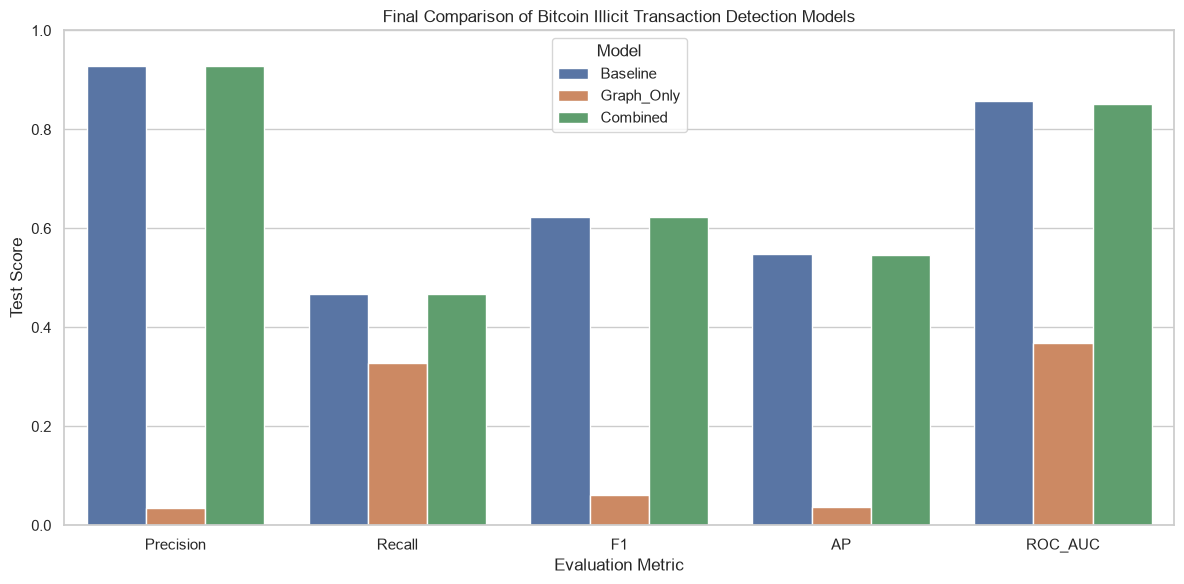

In [2]:
metrics = [
    "Precision", "Recall", "F1", "AP", "ROC_AUC"
]

final_comparison = results[
    ["Model"] + metrics
].copy()

display(final_comparison.round(4))

final_comparison.to_csv(
    TABLE_DIR / "22_final_research_comparison.csv",
    index=False
)

plot_data = final_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Final Comparison of Bitcoin Illicit Transaction Detection Models")
plt.ylabel("Test Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "26_final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Validation-to-test performance change

,Model,Validation_AP,Validation_ROC_AUC,AP,ROC_AUC,AP_Change,ROC_AUC_Change
0,Baseline,0.9304,0.9782,0.5479,0.8569,-0.3825,-0.1213
1,Graph_Only,0.1312,0.6059,0.0369,0.3676,-0.0942,-0.2383
2,Combined,0.9325,0.9798,0.5470,0.8522,-0.3855,-0.1277


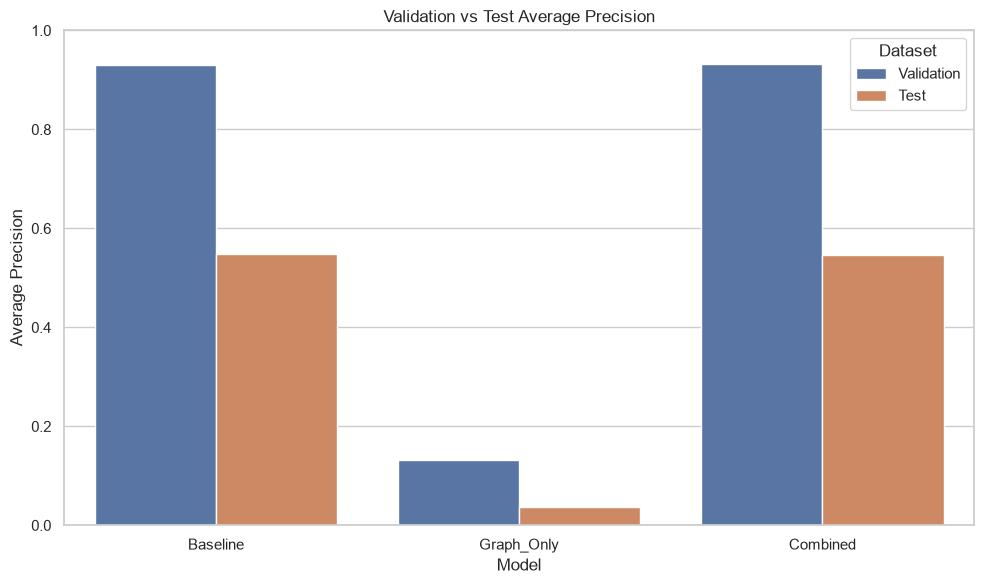

In [3]:
comparison = validation[
    ["Model", "Validation_AP", "Validation_ROC_AUC"]
].merge(
    results[["Model", "AP", "ROC_AUC"]],
    on="Model",
    validate="one_to_one"
)

comparison["AP_Change"] = (
    comparison["AP"] - comparison["Validation_AP"]
)

comparison["ROC_AUC_Change"] = (
    comparison["ROC_AUC"]
    - comparison["Validation_ROC_AUC"]
)

display(comparison.round(4))

comparison.to_csv(
    TABLE_DIR / "23_validation_test_performance_change.csv",
    index=False
)

plot_data = comparison.melt(
    id_vars="Model",
    value_vars=["Validation_AP", "AP"],
    var_name="Dataset",
    value_name="Average_Precision"
)

plot_data["Dataset"] = plot_data["Dataset"].replace({
    "Validation_AP": "Validation",
    "AP": "Test"
})

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Average_Precision",
    hue="Dataset"
)

plt.title("Validation vs Test Average Precision")
plt.ylabel("Average Precision")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "27_validation_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Measure the contribution of time step 42

,Model,time_step,Actual_Illicit,Correctly_Detected,Recall
0,Baseline,42,239,188,0.786611
1,Baseline,43,24,0,0.000000
2,Baseline,44,24,1,0.041667
3,Baseline,45,5,0,0.000000
4,Baseline,46,2,1,0.500000
5,Baseline,47,22,0,0.000000
6,Baseline,48,36,0,0.000000
7,Baseline,49,56,1,0.017857
8,Combined,42,239,188,0.786611
9,Combined,43,24,0,0.000000


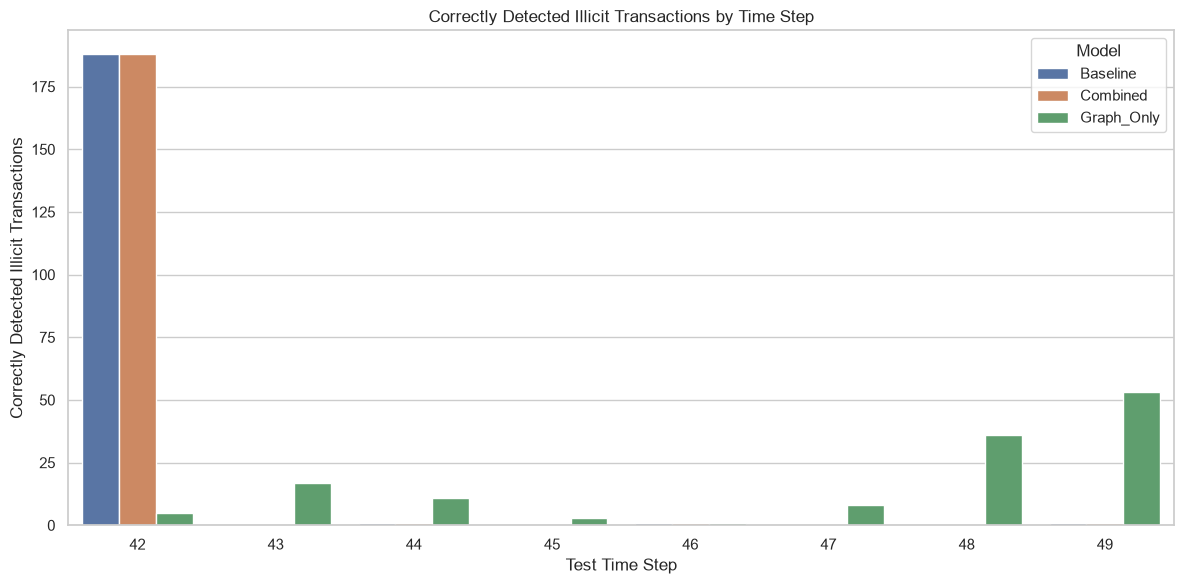

In [4]:
predictions = pd.read_csv(
    TABLE_DIR / "15_test_predictions.csv"
)

detection_summary = (
    predictions.assign(
        Correct_Illicit=lambda x: (
            (x["target"] == 1)
            & (x["Prediction"] == 1)
        ).astype(int)
    )
    .groupby(["Model", "time_step"])
    .agg(
        Actual_Illicit=("target", "sum"),
        Correctly_Detected=("Correct_Illicit", "sum")
    )
    .reset_index()
)

detection_summary["Recall"] = (
    detection_summary["Correctly_Detected"]
    / detection_summary["Actual_Illicit"].replace(0, np.nan)
)

display(detection_summary)

detection_summary.to_csv(
    TABLE_DIR / "24_detection_by_time_step.csv",
    index=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=detection_summary,
    x="time_step",
    y="Correctly_Detected",
    hue="Model"
)

plt.title("Correctly Detected Illicit Transactions by Time Step")
plt.xlabel("Test Time Step")
plt.ylabel("Correctly Detected Illicit Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "28_correct_detections_by_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Generate a research findings summary

In [5]:
baseline = results.set_index("Model").loc["Baseline"]
combined = results.set_index("Model").loc["Combined"]
graph_only = results.set_index("Model").loc["Graph_Only"]

summary = pd.DataFrame({
    "Research_Finding": [
        "Baseline Test AP",
        "Graph-only Test AP",
        "Combined Test AP",
        "Combined minus Baseline AP",
        "Combined minus Baseline F1",
        "Baseline Illicit Recall",
        "Baseline False Negatives",
        "Graph-only False Positives"
    ],
    "Value": [
        baseline["AP"],
        graph_only["AP"],
        combined["AP"],
        combined["AP"] - baseline["AP"],
        combined["F1"] - baseline["F1"],
        baseline["Recall"],
        baseline["FN"],
        graph_only["FP"]
    ]
})

display(summary)

summary.to_csv(
    TABLE_DIR / "25_final_research_findings.csv",
    index=False
)

print("Final research findings saved successfully.")

,Research_Finding,Value
0,Baseline Test AP,0.547887
1,Graph-only Test AP,0.036941
2,Combined Test AP,0.546983
3,Combined minus Baseline AP,-0.000904
4,Combined minus Baseline F1,0.000000
5,Baseline Illicit Recall,0.468137
6,Baseline False Negatives,217.000000
7,Graph-only False Positives,3789.000000


Final research findings saved successfully.


### Final validation

In [6]:
required_outputs = [
    "22_final_research_comparison.csv",
    "23_validation_test_performance_change.csv",
    "24_detection_by_time_step.csv",
    "25_final_research_findings.csv"
]

for filename in required_outputs:
    path = TABLE_DIR / filename

    print(
        ("PASS" if path.exists() else "CHECK"),
        filename
    )

print("\nNotebook 06 completed.")

PASS 22_final_research_comparison.csv
PASS 23_validation_test_performance_change.csv
PASS 24_detection_by_time_step.csv
PASS 25_final_research_findings.csv

Notebook 06 completed.
